In [ ]:
import sys
import os

for source_dir in (os.path.abspath("src"), os.path.abspath("../src")):
    if os.path.isdir(source_dir) and source_dir not in sys.path:
        sys.path.insert(0, source_dir)
        break

In [1]:
from openfc.components.fuelingSystem import FuelingSystem
from openfc.components.component import Component
from openfc.components.plasma import Plasma
from openfc.components.breedingBlanket import BreedingBlanket
from openfc.componentMap import ComponentMap
from matplotlib import pyplot as plt
from openfc.simulate import Simulate
import numpy as np
from openfc.tools.utils import visualize_connections

LAMBDA = 1.73e-9 # Decay constant for tritium
T_kg = 5.0081858248655999e-27
AF = 1
N_burn = 2.2649e20*T_kg * AF # Tritium burn rate in the plasma adjusted for AF - THIS IS IMPACTING THE RESERVE INVENTORY
TBR = 1.15

tau_ofc = 4 * 3600
tau_ifc = 8 * 3600

# General input parameters
I_startup = 1.5
TBE = 0.0199
final_time = 2.1 * 3600 * 24 * 365 # NB: longer than doubling time
q = 0.25
t_res = 24 * 3600
I_reserve = 1e-9 #N_burn/AF / TBE * q * t_res


# Define components
stor = FuelingSystem("Fueling System", N_burn, TBE, initial_inventory=I_startup)
OFC = BreedingBlanket("BB", tau_ofc, initial_inventory=0, N_burn = N_burn, TBR = TBR, non_radioactive_loss = 0)
plasma = Plasma("Plasma", N_burn, TBE, fp_fw=0.0, fp_div=0.0, non_radioactive_loss = 0, initial_inventory=0.0)   
IFC = Component("IFC", residence_time = tau_ifc, non_radioactive_loss = 0, initial_inventory=0.0)

# Define ports
port1 = stor.add_input_port("IFC-stor", incoming_fraction=1)
port2 = stor.add_output_port("Fueling to Plasma")

port3 = plasma.add_input_port("Stor-Plasma", incoming_fraction= (1))
port4 = plasma.add_output_port("Plasma to IFC")

port5 = OFC.add_input_port("BB to OFC", incoming_fraction=1)
port6 = OFC.add_output_port("OFC to IFC")

port7 = IFC.add_input_port("Plasma to IFC", incoming_fraction=1)
port8 = IFC.add_input_port("OFC to IFC", incoming_fraction=1)
port9 = IFC.add_output_port("IFC to Stor")

# Add components to component map
component_map = ComponentMap()
component_map.add_component(stor)
component_map.add_component(OFC)
component_map.add_component(IFC)
component_map.add_component(plasma)

# Connect ports
component_map.connect_ports(stor, port2, plasma, port3)
component_map.connect_ports(plasma, port4, IFC, port7)
component_map.connect_ports(OFC, port6, IFC, port8)
component_map.connect_ports(IFC, port9, stor, port1)


Component: Fueling System
  Port: Fueling to Plasma -> Connected Component: Plasma, Connected Port: Stor-Plasma
  Port: IFC-stor -> Connected Component: IFC, Connected Port: IFC to Stor
Component: Plasma
  Port: Stor-Plasma -> Connected Component: Fueling System, Connected Port: Fueling to Plasma
  Port: Plasma to IFC -> Connected Component: IFC, Connected Port: Plasma to IFC
Component: IFC
  Port: Plasma to IFC -> Connected Component: Plasma, Connected Port: Plasma to IFC
  Port: OFC to IFC -> Connected Component: BB, Connected Port: OFC to IFC
  Port: IFC to Stor -> Connected Component: Fueling System, Connected Port: IFC-stor
Component: BB
  Port: OFC to IFC -> Connected Component: IFC, Connected Port: OFC to IFC


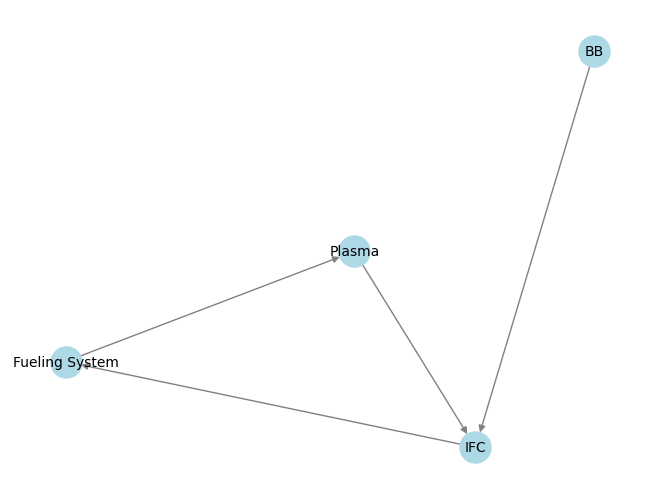

In [2]:
component_map.print_connected_map()
visualize_connections(component_map)

In [3]:
print(f'Startup inventory is: {stor.tritium_inventory}')
simulation = Simulate(dt=0.00001, dt_max = 100000, final_time=final_time, I_reserve=I_reserve, component_map=component_map, max_simulations=2)
t, y = simulation.run()
# np.savetxt('tritium_inventory.txt', [t,y], delimiter=',')


Startup inventory is: 1.5
Initial inventories = [1.5, 0, 0.0, 0.0] kg
I_0 = 1.5 kgror = 1.8515166382051213e-19, dt = 1e-05, dt_new = 54009776.59965346
Doubling time: 0.6341660109576747 

Startup inventory is: 1.5 

Error: Tritium inventory in Fueling System is below zero. Difference is -0.13383098420927328 kg
Updated I_startup to 1.6338309842092733
Initial inventories = [np.float64(1.6338309842092733), 0, 0.0, 0.0] kg
I_0 = 1.6338309842092733 kg, Error = 8.201485987368925e-13, dt = 0.017487955183034174, dt_new = 21322.91051885878
Doubling time: 0.6625275019973492 

Startup inventory is: 1.6338309842092733 



In [4]:
print(f"doubling time is: {t[np.where(np.array(y)[:,0] > 2*I_startup)[0][0]]/3600/24/365} years = {t[np.where(np.array(y)[:,0] > 2*I_startup)[0][0]]/3600/24} days = {t[np.where(np.array(y)[:,0] > 2*I_startup)[0][0]]/3600} hours = {t[np.where(np.array(y)[:,0] > 2*I_startup)[0][0]]} seconds")

doubling time is: 0.6083671923199934 years = 222.0540251967976 days = 5329.296604723142 hours = 19185467.77700331 seconds


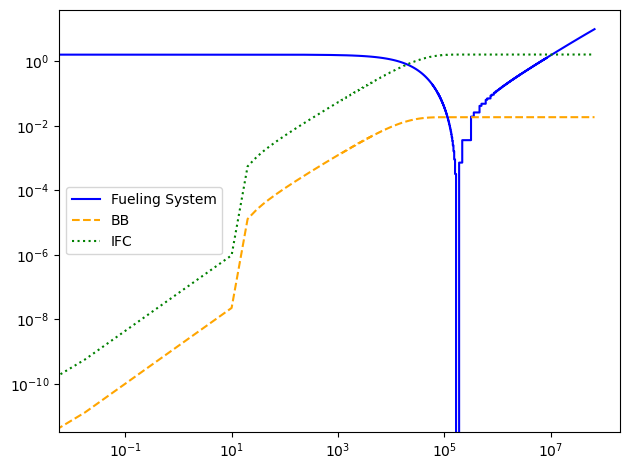

Component inventories: dict_keys(['Fueling System', 'BB', 'IFC', 'Plasma']): [1.00599054e+01 1.87817479e-02 1.64641923e+00 4.62110495e-13]

Component: Fueling System, inflow: 0.0001 kg/s, outflow: 0.0001 kg/s
Component: BB, inflow: 0.0000 kg/s, outflow: 0.0000 kg/s
Component: IFC, inflow: 0.0001 kg/s, outflow: 0.0001 kg/s
Component: Plasma, inflow: 0.0001 kg/s, outflow: 0.0001 kg/s


In [5]:

combinations = [
    ('b', '-'), ('orange', '--'), ('g', ':'), #('r', '-.'), 
    # ('purple', '-'), ('brown', '--'), ('pink', ':'), ('gray', '-.'), 
    # ('olive', '-'), ('c', '--'), ('navy', ':'), ('maroon', '-.')
]

fig,ax = plt.subplots()
for i, (color, linestyle) in enumerate(combinations):
    ax.loglog(t, np.array(y)[:,i], color=color, linestyle=linestyle)
# ax.loglog(t, y)
ax.legend(component_map.components.keys())
fig.tight_layout()

plt.show()

print(f"Component inventories: {component_map.components.keys()}: {y[-1]}\n")

for component in component_map.components.values():
    print(f"Component: {component.name}, inflow: {component.inflow[-1]:.4f} kg/s, outflow: {component.outflow[-1]:.4f} kg/s")
